In [13]:
from pathlib import Path
import pandas as pd
import numpy as np

files = sorted(Path("phaseclass").glob("*.csv"))

all_beta = []

for file in files:
    df = pd.read_csv(file)

    beta = df["beta_deg"].dropna().abs()

    all_beta.extend(beta.values)

all_beta = np.array(all_beta)

for threshold in [3, 5, 7, 10, 12, 15, 20]:
    print(
        f"|β| >= {threshold:2d}° : "
        f"{(all_beta >= threshold).mean()*100:.2f}%"
    )

|β| >=  3° : 5.67%
|β| >=  5° : 0.49%
|β| >=  7° : 0.07%
|β| >= 10° : 0.02%
|β| >= 12° : 0.01%
|β| >= 15° : 0.00%
|β| >= 20° : 0.00%


In [14]:
from pathlib import Path
import pandas as pd

files = sorted(Path("phaseclass").glob("*.csv"))

for file in files:
    df = pd.read_csv(file)

    beta = df["beta_deg"].dropna().abs()

    print(
        f"{file.name:20s}",
        f"max |β| = {beta.max():8.3f}°",
        f"95% = {beta.quantile(0.95):8.3f}°",
        f"99% = {beta.quantile(0.99):8.3f}°"
    )

2023-10_1_phaseclass.csv max |β| =    4.436° 95% =    2.917° 99% =    3.837°
2023-10_2_phaseclass.csv max |β| =   12.957° 95% =    2.975° 99% =    4.051°
2023-10_3_phaseclass.csv max |β| =    4.436° 95% =    2.917° 99% =    3.837°
2023-10_4_phaseclass.csv max |β| =   23.688° 95% =    3.079° 99% =    6.359°
2023-10_5_phaseclass.csv max |β| =   12.277° 95% =    3.441° 99% =    4.938°
2023-10_6_phaseclass.csv max |β| =   10.256° 95% =    3.913° 99% =    5.453°
2023-10_7_phaseclass.csv max |β| =   12.086° 95% =    3.634° 99% =    5.018°
2023-10_8_phaseclass.csv max |β| =   12.397° 95% =    3.748° 99% =    4.810°
2023-10_9_phaseclass.csv max |β| =   12.045° 95% =    2.949° 99% =    3.800°
2023-10_phaseclass.csv max |β| =   12.957° 95% =    2.975° 99% =    4.051°
2023-11_10_phaseclass.csv max |β| =   15.572° 95% =    2.602° 99% =    3.491°
2023-11_11_phaseclass.csv max |β| =    8.265° 95% =    2.594° 99% =    3.826°
2023-11_1_phaseclass.csv max |β| =   14.159° 95% =    2.923° 99% =    4.221°

In [15]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path(".")
PHASE_DIR = BASE / "phaseclass"

raw_files = sorted(
    list((BASE / "Oct2023").glob("*.csv")) +
    list((BASE / "Nov2023").glob("*.csv"))
)

phase_files = sorted(PHASE_DIR.glob("*_phaseclass.csv"))

print("Raw files:", len(raw_files))
print("Phase files:", len(phase_files))

for phase_file in phase_files:

    raw_name = phase_file.stem.replace("_phaseclass", "")

    matches = [
        f for f in raw_files
        if f.stem == raw_name
    ]

    if len(matches) == 0:
        print("RAW FILE NOT FOUND:", raw_name)
        continue

    raw_file = matches[0]

    raw = pd.read_csv(raw_file, skiprows=2)
    phase = pd.read_csv(phase_file)

    if "slipAngle_rad" not in raw.columns:
        print("slipAngle_rad NOT FOUND:", raw_file.name)
        continue

    if "beta_deg" not in phase.columns:
        print("beta_deg NOT FOUND:", phase_file.name)
        continue

    if len(raw) != len(phase):
        print(
            f"{phase_file.name}: ROW COUNT MISMATCH "
            f"raw={len(raw)}, phase={len(phase)}"
        )
        continue

    if not np.allclose(
        raw["t_s"].values,
        phase["t_s"].values,
        equal_nan=True
    ):
        print("TIME MISMATCH:", phase_file.name)
        continue

    slip_deg = np.degrees(raw["slipAngle_rad"])
    beta = phase["beta_deg"]

    valid = beta.notna() & slip_deg.notna()

    print(
        f"{phase_file.name:30s}"
        f" | rows={len(raw):7d}"
        f" | β max={beta[valid].abs().max():7.3f}°"
        f" | slip max={slip_deg[valid].abs().max():7.3f}°"
        f" | β mean={beta[valid].abs().mean():7.3f}°"
        f" | slip mean={slip_deg[valid].abs().mean():7.3f}°"
    )

Raw files: 22
Phase files: 22
2023-10_1_phaseclass.csv       | rows=  23156 | β max=  4.436° | slip max=  4.436° | β mean=  1.209° | slip mean=  1.209°
2023-10_2_phaseclass.csv       | rows=  22866 | β max= 12.957° | slip max=  4.863° | β mean=  1.255° | slip mean=  1.213°
2023-10_3_phaseclass.csv       | rows=  23156 | β max=  4.436° | slip max=  4.436° | β mean=  1.209° | slip mean=  1.209°
2023-10_4_phaseclass.csv       | rows=  23345 | β max= 23.688° | slip max=  8.474° | β mean=  1.360° | slip mean=  1.294°
2023-10_5_phaseclass.csv       | rows=  46484 | β max= 12.277° | slip max=  6.438° | β mean=  1.202° | slip mean=  1.178°
2023-10_6_phaseclass.csv       | rows=  22115 | β max= 10.256° | slip max=  6.725° | β mean=  1.431° | slip mean=  1.352°
2023-10_7_phaseclass.csv       | rows=  26996 | β max= 12.086° | slip max=  5.764° | β mean=  1.263° | slip mean=  1.231°
2023-10_8_phaseclass.csv       | rows=  42365 | β max= 12.397° | slip max=  5.833° | β mean=  1.475° | slip mean=  1

In [16]:
from pathlib import Path
import pandas as pd

files = sorted(Path("phaseclass").glob("*.csv"))

for file in files:
    df = pd.read_csv(file)

    beta = df["beta_deg"].abs()

    print(
        f"{file.name:30s}"
        f" max={beta.max():8.3f}°"
        f" 95%={beta.quantile(0.95):8.3f}°"
        f" 99%={beta.quantile(0.99):8.3f}°"
    )

2023-10_1_phaseclass.csv       max=   4.436° 95%=   2.917° 99%=   3.837°
2023-10_2_phaseclass.csv       max=  12.957° 95%=   2.975° 99%=   4.051°
2023-10_3_phaseclass.csv       max=   4.436° 95%=   2.917° 99%=   3.837°
2023-10_4_phaseclass.csv       max=  23.688° 95%=   3.079° 99%=   6.359°
2023-10_5_phaseclass.csv       max=  12.277° 95%=   3.441° 99%=   4.938°
2023-10_6_phaseclass.csv       max=  10.256° 95%=   3.913° 99%=   5.453°
2023-10_7_phaseclass.csv       max=  12.086° 95%=   3.634° 99%=   5.018°
2023-10_8_phaseclass.csv       max=  12.397° 95%=   3.748° 99%=   4.810°
2023-10_9_phaseclass.csv       max=  12.045° 95%=   2.949° 99%=   3.800°
2023-10_phaseclass.csv         max=  12.957° 95%=   2.975° 99%=   4.051°
2023-11_10_phaseclass.csv      max=  15.572° 95%=   2.602° 99%=   3.491°
2023-11_11_phaseclass.csv      max=   8.265° 95%=   2.594° 99%=   3.826°
2023-11_1_phaseclass.csv       max=  14.159° 95%=   2.923° 99%=   4.221°
2023-11_2_phaseclass.csv       max=  16.761° 95%=  

In [17]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path(".")
PHASE_DIR = BASE / "phaseclass"

raw_files = sorted(
    list((BASE / "Oct2023").glob("*.csv")) +
    list((BASE / "Nov2023").glob("*.csv"))
)

phase_files = sorted(PHASE_DIR.glob("*_phaseclass.csv"))

results = []

for phase_file in phase_files:

    raw_name = phase_file.stem.replace("_phaseclass", "")

    matches = [f for f in raw_files if f.stem == raw_name]

    if not matches:
        continue

    raw_file = matches[0]

    raw = pd.read_csv(raw_file, skiprows=2)
    phase = pd.read_csv(phase_file)

    if len(raw) != len(phase):
        print("ROW MISMATCH:", phase_file.name)
        continue

    slip_deg = np.degrees(raw["slipAngle_rad"].values)
    beta_deg = phase["beta_deg"].values

    valid = np.isfinite(slip_deg) & np.isfinite(beta_deg)

    results.append({
        "file": phase_file.name,
        "max_beta": np.max(np.abs(beta_deg[valid])),
        "max_slip": np.max(np.abs(slip_deg[valid])),
        "p99_beta": np.percentile(np.abs(beta_deg[valid]), 99),
        "p99_slip": np.percentile(np.abs(slip_deg[valid]), 99)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "max_slip",
    ascending=False
)

results_df

,file,max_beta,max_slip,p99_beta,p99_slip
3,2023-10_4_phaseclass.csv,23.688227,8.474280,6.358576,5.177034
21,2023-11_phaseclass.csv,19.167602,6.802573,3.316085,3.133306
5,2023-10_6_phaseclass.csv,10.256433,6.724990,5.452830,5.107797
4,2023-10_5_phaseclass.csv,12.277322,6.438392,4.937807,4.844810
7,2023-10_8_phaseclass.csv,12.396852,5.833440,4.810171,4.798407
6,2023-10_7_phaseclass.csv,12.086354,5.763800,5.017708,4.846688
12,2023-11_1_phaseclass.csv,14.159175,5.601614,4.220894,4.175901
13,2023-11_2_phaseclass.csv,16.761276,5.510385,4.956953,4.917890
14,2023-11_3_phaseclass.csv,14.521766,5.422297,4.755847,4.706489
15,2023-11_4_phaseclass.csv,13.526617,5.127714,4.173407,4.168195


Strongest file: 2023-10_4_phaseclass.csv
Maximum |slip angle|: 8.474280223341866


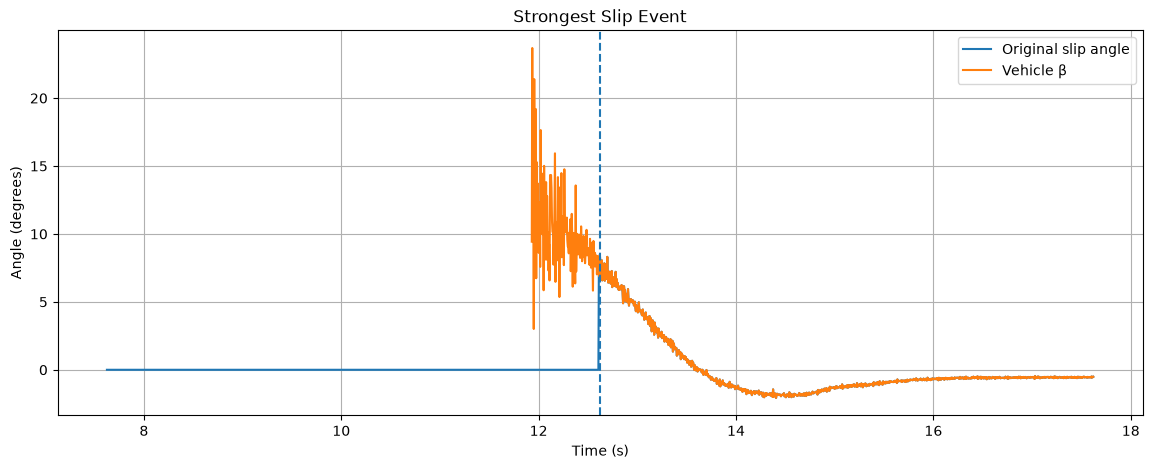

In [18]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = Path(".")
PHASE_DIR = BASE / "phaseclass"

raw_files = sorted(
    list((BASE / "Oct2023").glob("*.csv")) +
    list((BASE / "Nov2023").glob("*.csv"))
)

phase_files = sorted(PHASE_DIR.glob("*_phaseclass.csv"))

best_file = None
best_slip = -1

for phase_file in phase_files:

    raw_name = phase_file.stem.replace("_phaseclass", "")

    matches = [f for f in raw_files if f.stem == raw_name]

    if not matches:
        continue

    raw = pd.read_csv(matches[0], skiprows=2)
    phase = pd.read_csv(phase_file)

    if len(raw) != len(phase):
        continue

    slip_deg = np.degrees(raw["slipAngle_rad"].values)

    current_max = np.nanmax(np.abs(slip_deg))

    if current_max > best_slip:
        best_slip = current_max
        best_file = phase_file

print("Strongest file:", best_file.name)
print("Maximum |slip angle|:", best_slip)

raw_name = best_file.stem.replace("_phaseclass", "")
raw_file = next(f for f in raw_files if f.stem == raw_name)

raw = pd.read_csv(raw_file, skiprows=2)
phase = pd.read_csv(best_file)

slip_deg = np.degrees(raw["slipAngle_rad"])

peak_index = np.nanargmax(np.abs(slip_deg))

time_peak = raw["t_s"].iloc[peak_index]

window = 5

mask = (
    (raw["t_s"] >= time_peak - window) &
    (raw["t_s"] <= time_peak + window)
)

plt.figure(figsize=(14, 5))

plt.plot(
    raw.loc[mask, "t_s"],
    slip_deg.loc[mask],
    label="Original slip angle"
)

plt.plot(
    phase.loc[mask, "t_s"],
    phase.loc[mask, "beta_deg"],
    label="Vehicle β"
)

plt.axvline(
    time_peak,
    linestyle="--"
)

plt.xlabel("Time (s)")
plt.ylabel("Angle (degrees)")
plt.title("Strongest Slip Event")
plt.legend()
plt.grid()
plt.show()

In [19]:
from pathlib import Path
import pandas as pd
import numpy as np

files = sorted(Path("phaseclass").glob("*.csv"))

for file in files:

    df = pd.read_csv(file)

    df["beta_rate_degps"] = (
        df["beta_deg"].diff() /
        df["t_s"].diff()
    )

    df["beta_rate_degps"] = (
        df["beta_rate_degps"]
        .replace([np.inf, -np.inf], np.nan)
    )

    df.to_csv(file, index=False)

print("beta_rate_degps added to", len(files), "files")

beta_rate_degps added to 22 files


In [20]:
df = pd.read_csv(files[0])

print(
    df[
        ["t_s", "beta_deg", "beta_rate_degps"]
    ].head(20)
)

         t_s  beta_deg  beta_rate_degps
0   0.000000 -0.418340              NaN
1   0.004999 -0.612899       -38.919600
2   0.009998 -0.406502        41.287753
3   0.014997 -0.508933       -20.490396
4   0.019996 -0.508951        -0.003486
5   0.024995 -0.599853       -18.183806
6   0.029994 -0.609852        -2.000145
7   0.034993 -0.507201        20.534314
8   0.039992 -0.598278       -18.219052
9   0.044991 -0.598320        -0.008301
10  0.049990 -0.380688        43.534247
11  0.054989 -0.380688         0.000000
12  0.059988 -0.689767       -61.828220
13  0.064987 -0.378610        62.242551
14  0.069986 -0.575025       -39.290850
15  0.074985 -0.481805        18.647676
16  0.079984 -0.481805         0.000000
17  0.084983 -0.573304       -18.303439
18  0.089982 -0.469955        20.674016
19  0.094981 -0.573324       -20.677510


LABELS

In [21]:
from pathlib import Path
import pandas as pd
import numpy as np

files = sorted(Path("phaseclass").glob("*.csv"))

for file in files:

    df = pd.read_csv(file)

    abs_beta = df["beta_deg"].abs()

    beta_rate = (
        abs_beta.diff() /
        df["t_s"].diff()
    )

    beta_rate = beta_rate.replace(
        [np.inf, -np.inf],
        np.nan
    )

    labels = np.full(len(df), "NORMAL", dtype=object)

    initiating = (
        (abs_beta >= 3) &
        (beta_rate > 2)
    )

    sustained = (
        (abs_beta >= 5) &
        (beta_rate.abs() <= 2)
    )

    labels[initiating] = "INITIATING_DRIFT"
    labels[sustained] = "SUSTAINED_DRIFT"

    df["beta_rate_degps"] = beta_rate
    df["phase_label"] = labels

    df.to_csv(file, index=False)

print("Labels added to", len(files), "files")

Labels added to 22 files


In [22]:
from pathlib import Path
import pandas as pd

files = sorted(Path("phaseclass").glob("*.csv"))

all_labels = []

for file in files:
    df = pd.read_csv(file)
    all_labels.extend(df["phase_label"])

labels = pd.Series(all_labels)

print(labels.value_counts())
print()
print(labels.value_counts(normalize=True) * 100)

NORMAL              531956
INITIATING_DRIFT     13535
SUSTAINED_DRIFT        284
Name: count, dtype: int64

NORMAL              97.468004
INITIATING_DRIFT     2.479960
SUSTAINED_DRIFT      0.052036
Name: proportion, dtype: float64


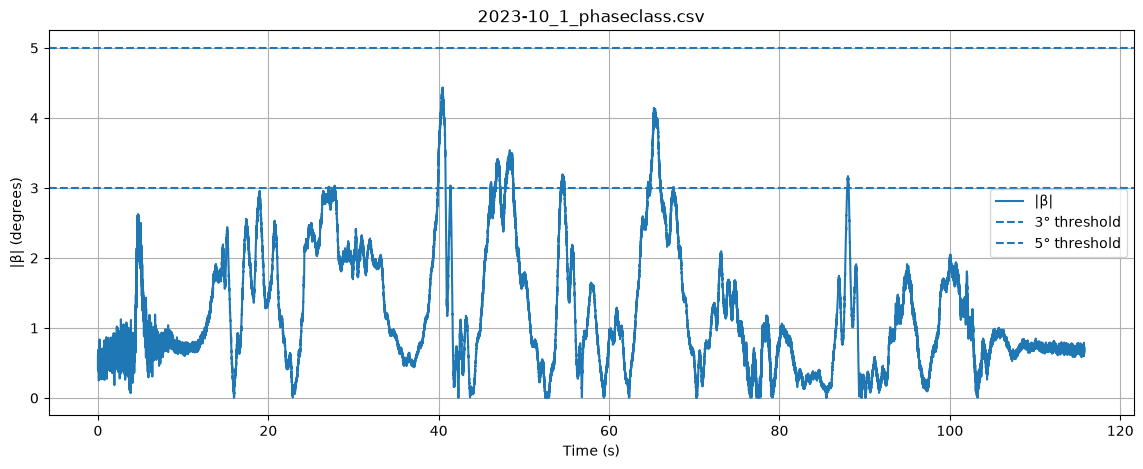

In [23]:
import matplotlib.pyplot as plt

file = sorted(Path("phaseclass").glob("*.csv"))[0]
df = pd.read_csv(file)

plt.figure(figsize=(14, 5))

plt.plot(
    df["t_s"],
    df["beta_deg"].abs(),
    label="|β|"
)

plt.axhline(3, linestyle="--", label="3° threshold")
plt.axhline(5, linestyle="--", label="5° threshold")

plt.xlabel("Time (s)")
plt.ylabel("|β| (degrees)")
plt.title(file.name)
plt.legend()
plt.grid()
plt.show()